# **Fraud Detection in Financial Transactions Using Apache Spark and Machine Learning**

**Aim**

The aim of this project is to develop and evaluate machine-learning models for detecting fraudulent online transction using Apache Spark

**Objectives**

* Load and explore the IEEE-CIS Fraud Detection Dataset.
* Merge transction and identity information.
* Investigate class imbalance and missing values.
* Use Spark SQL for focused exploratory analysis.
* Prepare selected features for machine learning.
* Train Logistic Regression, Decision Tree and Rondom Forest models.
* Evaluate the models using suitables fraud-detection metrics.
* Compare the models and identify the most suitable model.

**Notebook Structure**
1. Data loading
2. Data understanding
3. Exploratory data analysis
4. Missing-value treatment
5. Feature prepration
6. Class-imbalance treatment
7. Model training
8. Model evaluation
9. Model comparison
10. Conclusion

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/farhad872/fraud-dataset-fyp/train_identity.csv
/kaggle/input/datasets/farhad872/fraud-dataset-fyp/train_transaction.csv


## 1 .Install PySpark

In [2]:
# Install PySpark in the Kaggle enviroment
!pip install pyspark

## 2. Import Libraries

In [3]:
#Spark libraries
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, count, desc

#Spark machine-learning libraries
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator,  MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics

# Phython libraries
import os
import glob
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Create Spark Session

In [4]:
# Create the Spark Session
spark = ( SparkSession.builder.appName("Fraud Detection Project").getOrCreate())

# Hide unnecessary Spark Warning messsages
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/02 09:48:50 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 4. Loading the Dataset

In [5]:
# Load the transaction dataset
transaction_df = spark.read.csv("/kaggle/input/datasets/farhad872/fraud-dataset-fyp/train_transaction.csv", header=True, inferSchema=True)

# Load the identity dataset
identity_df = spark.read.csv("/kaggle/input/datasets/farhad872/fraud-dataset-fyp/train_identity.csv", header=True, inferSchema=True)


## 5. Display Sample Records

In [6]:
# Display sample transaction records
transaction_df.show(5, truncate=False)

+-------------+-------+-------------+--------------+---------+-----+-----+-----+----------+-----+------+-----+-----+-----+-----+-------------+-------------+---+---+---+---+---+---+---+---+---+---+---+---+----+---+-----+-----+----+----+----+----+----+----+----+----+-----+----+----+----+-----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+---+----+----+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+------+-----+----+-----+-----+----+

In [7]:
# Display sample identity records
identity_df.show(5, truncate=False)

+-------------+-----+--------+-----+-----+-----+-----+-----+-----+-----+-----+-----+--------+-----+------+-----+--------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+--------+----------------+-------------------+-----+---------+--------------+-----+-----+-----+-----+----------+-----------------------------+
|TransactionID|id_01|id_02   |id_03|id_04|id_05|id_06|id_07|id_08|id_09|id_10|id_11|id_12   |id_13|id_14 |id_15|id_16   |id_17|id_18|id_19|id_20|id_21|id_22|id_23|id_24|id_25|id_26|id_27|id_28|id_29   |id_30           |id_31              |id_32|id_33    |id_34         |id_35|id_36|id_37|id_38|DeviceType|DeviceInfo                   |
+-------------+-----+--------+-----+-----+-----+-----+-----+-----+-----+-----+-----+--------+-----+------+-----+--------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-----+--------+----------------+-------------------+-----+---------+--------------+-----+-----+-----+-----+----------+-----------------------

## 6. Check Data Types

In [8]:
# Display the transaction Schema
transaction_df.printSchema()

root
 |-- TransactionID: integer (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- TransactionDT: integer (nullable = true)
 |-- TransactionAmt: double (nullable = true)
 |-- ProductCD: string (nullable = true)
 |-- card1: integer (nullable = true)
 |-- card2: double (nullable = true)
 |-- card3: double (nullable = true)
 |-- card4: string (nullable = true)
 |-- card5: double (nullable = true)
 |-- card6: string (nullable = true)
 |-- addr1: double (nullable = true)
 |-- addr2: double (nullable = true)
 |-- dist1: double (nullable = true)
 |-- dist2: double (nullable = true)
 |-- P_emaildomain: string (nullable = true)
 |-- R_emaildomain: string (nullable = true)
 |-- C1: double (nullable = true)
 |-- C2: double (nullable = true)
 |-- C3: double (nullable = true)
 |-- C4: double (nullable = true)
 |-- C5: double (nullable = true)
 |-- C6: double (nullable = true)
 |-- C7: double (nullable = true)
 |-- C8: double (nullable = true)
 |-- C9: double (nullable = true)
 |-- C10:

In [9]:
# Display the identity schema
identity_df.printSchema()

root
 |-- TransactionID: integer (nullable = true)
 |-- id_01: double (nullable = true)
 |-- id_02: double (nullable = true)
 |-- id_03: double (nullable = true)
 |-- id_04: double (nullable = true)
 |-- id_05: double (nullable = true)
 |-- id_06: double (nullable = true)
 |-- id_07: double (nullable = true)
 |-- id_08: double (nullable = true)
 |-- id_09: double (nullable = true)
 |-- id_10: double (nullable = true)
 |-- id_11: double (nullable = true)
 |-- id_12: string (nullable = true)
 |-- id_13: double (nullable = true)
 |-- id_14: double (nullable = true)
 |-- id_15: string (nullable = true)
 |-- id_16: string (nullable = true)
 |-- id_17: double (nullable = true)
 |-- id_18: double (nullable = true)
 |-- id_19: double (nullable = true)
 |-- id_20: double (nullable = true)
 |-- id_21: double (nullable = true)
 |-- id_22: double (nullable = true)
 |-- id_23: string (nullable = true)
 |-- id_24: double (nullable = true)
 |-- id_25: double (nullable = true)
 |-- id_26: double (null

## 7. Check Dataset Size

In [10]:
# Count rows and columns
transaction_rows = transaction_df.count()
indentity_rows = identity_df.count()

print("Transaction dataset")
print("Rows:", transaction_rows)
print( "Columns:", len(transaction_df.columns))

print("\nIdentity dataset")
print("Rows:", indentity_rows)
print("Column:", len(identity_df.columns))

Transaction dataset
Rows: 590540
Columns: 394

Identity dataset
Rows: 144233
Column: 41


## 8. Merge the Datasets

The datasets are joined using TransactionID.

A left join is used because the transacion table contains the target variable isFraud. This keeps every transaction, even where identity information is unavailable.

In [11]:
# Merge transaction and identity data
fraud_df = transaction_df.join(identity_df, on="TransactionID", how="left")

fraud_df.show(5, truncate=False)


+-------------+-------+-------------+--------------+---------+-----+-----+-----+----------+-----+------+-----+-----+-----+-----+-------------+-------------+---+---+---+---+---+---+---+---+---+---+---+---+----+---+-----+-----+----+----+----+----+----+----+----+-----+----+----+----+----+-----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+---+----+----+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+-----------------+-----------------+----

In [12]:
print("Merged rows:", fraud_df.count())
print("Merged columns:", len(fraud_df.columns))

Merged rows: 590540
Merged columns: 434


The number of rows remians equal to the transaction dataset because a left join keeps every transaction. Missing identity information appears  as NULL.

## 9. Check Duplicate Transaction IDS


In [13]:
total_rows = fraud_df.count()
unique_id = fraud_df.select("TransactionID").distinct().count()
duplicate_rows = total_rows - unique_id

print("Total rows:", total_rows)
print("unique Transaction IDs:", unique_id)
print("Duplicate Transaction IDs:", duplicate_rows)

Total rows: 590540
unique Transaction IDs: 590540
Duplicate Transaction IDs: 0


## 10. Checking Msissing Values

In [14]:
missing_values_df = fraud_df.select([count(when(col(c).isNull(), c))
                                     .alias(c) for c in fraud_df.columns])

missing_values_df.show(vertical=True)

-RECORD 0----------------
 TransactionID  | 0      
 isFraud        | 0      
 TransactionDT  | 0      
 TransactionAmt | 0      
 ProductCD      | 0      
 card1          | 0      
 card2          | 8933   
 card3          | 1565   
 card4          | 1577   
 card5          | 4259   
 card6          | 1571   
 addr1          | 65706  
 addr2          | 65706  
 dist1          | 352271 
 dist2          | 552913 
 P_emaildomain  | 94456  
 R_emaildomain  | 453249 
 C1             | 0      
 C2             | 0      
 C3             | 0      
 C4             | 0      
 C5             | 0      
 C6             | 0      
 C7             | 0      
 C8             | 0      
 C9             | 0      
 C10            | 0      
 C11            | 0      
 C12            | 0      
 C13            | 0      
 C14            | 0      
 D1             | 1269   
 D2             | 280797 
 D3             | 262878 
 D4             | 168922 
 D5             | 309841 
 D6             | 517353 
 D7         

## 11. Create Missing-Value Summary

In [15]:
missing_values_dict = missing_values_df.first().asDict()
selected_row_count = fraud_df.count()

missing_summary = pd.DataFrame({
    "Column": list(missing_values_dict.keys()),
    "Missing Values": list(missing_values_dict.values())})

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Values"] / selected_row_count * 100
). round (2)

missing_summary = missing_summary.sort_values("Missing Percentage",
                                             )

missing_summary = missing_summary.reset_index(drop=True)

missing_summary


,Column,Missing Values,Missing Percentage
0,TransactionID,0,0.00
1,isFraud,0,0.00
2,C2,0,0.00
3,C3,0,0.00
4,C4,0,0.00
...,...,...,...
429,id_26,585377,99.13
430,id_07,585385,99.13
431,id_08,585385,99.13
432,id_21,585381,99.13


In [16]:
# Select the features for machine learning

selected_df = fraud_df.select(
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
    "card1",
    "card2",
    "card3",
    "card4",
    "card5",
    "card6",
    "addr1",
    "addr2",
    "dist1",
    "C1",
    "C2",
    "C5",
    "C11",
    "C13",
    "C14",
    "D1",
    "D2",
    "D3",
    "D4",
    "D10",
    "D15",
    "DeviceType"
)

print("Rows:", selected_df.count())
print("Columns:", len(selected_df.columns))

Rows: 590540
Columns: 27


## 12 Split the Data

Missing values were identified across several numerical and categorical features. Numerical features will be imputed using the median, while categorical features will be imputed using the mode. To avoid data leakage, the dataset is split before calculating the imputation values.

In [17]:
#Split into 80% training and 20% testing data
training_df, testing_df = selected_df. randomSplit([0.80, 0.20], seed=42)

print("Training rows:", training_df.count())
print("Testing rows:", testing_df.count())

Training rows: 472404


Testing rows: 118136


## 13. Handle Missing Values

 * Numerical missing values are replaced using the median calculated from the training data.
 
* Categorical missing values are replaced using the mode calculated from the training data.

* The same replacement values are applied to the testing data.

In [18]:
# Numerical columns

numerical_columns = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "C1",
    "C2",
    "C5",
    "C11",
    "C13",
    "C14",
    "D1",
    "D2",
    "D3",
    "D4",
    "D10",
    "D15"
]

In [19]:
# Store the median for each numerical column
median_values ={}

#Calculate the median for each numerical column

for column in numerical_columns:
    median = training_df.approxQuantile(column,[0.5], 0.01)[0]
    median_values[column] = median



In [20]:
#Replace missing numerical values
training_df = training_df.fillna(median_values)
testing_df = testing_df.fillna(median_values)

print("Median values used:")
for column, median in median_values.items():
    print(column, ":", median)

Median values used:
TransactionDT : 7234651.0
TransactionAmt : 67.95
card1 : 9633.0
card2 : 361.0
card3 : 150.0
card5 : 226.0
addr1 : 299.0
addr2 : 87.0
dist1 : 8.0
C1 : 1.0
C2 : 1.0
C5 : 0.0
C11 : 1.0
C13 : 3.0
C14 : 1.0
D1 : 2.0
D2 : 95.0
D3 : 8.0
D4 : 24.0
D10 : 14.0
D15 : 50.0


In [21]:
# Categorical columns

categorical_columns = [
    "ProductCD",
    "card4",
    "card6",
    "DeviceType"
]

In [22]:
# Store the mode for each categorical column

mode_values = {}

for column in categorical_columns:
    mode = (training_df.filter(col(column).isNotNull()).groupBy(column).count()
           .orderBy("count", ascending=False).first()[0])
    mode_values[column] = mode

In [23]:
#Replace missing categorical values
training_df = training_df.fillna(mode_values)
testing_df = testing_df.fillna(mode_values)

print("Mode values used:")
for column, mode in mode_values.items():
    print(column, ":", mode)

Mode values used:
ProductCD : W
card4 : visa
card6 : debit
DeviceType : desktop


In [24]:
#Checking the missing values for training and testing data

print("Training Data")
training_df.select([count(when(col(c).isNull(), c)).alias(c) 
                   for c in training_df.columns]).show(vertical=True)

print ("Testing Data")
testing_df.select([count(when(col(c).isNull(), c)).alias(c)
                  for c in testing_df.columns]).show(vertical=True)




Training Data


-RECORD 0-------------
 TransactionID  | 0   
 isFraud        | 0   
 TransactionDT  | 0   
 TransactionAmt | 0   
 ProductCD      | 0   
 card1          | 0   
 card2          | 0   
 card3          | 0   
 card4          | 0   
 card5          | 0   
 card6          | 0   
 addr1          | 0   
 addr2          | 0   
 dist1          | 0   
 C1             | 0   
 C2             | 0   
 C5             | 0   
 C11            | 0   
 C13            | 0   
 C14            | 0   
 D1             | 0   
 D2             | 0   
 D3             | 0   
 D4             | 0   
 D10            | 0   
 D15            | 0   
 DeviceType     | 0   

Testing Data


-RECORD 0-------------
 TransactionID  | 0   
 isFraud        | 0   
 TransactionDT  | 0   
 TransactionAmt | 0   
 ProductCD      | 0   
 card1          | 0   
 card2          | 0   
 card3          | 0   
 card4          | 0   
 card5          | 0   
 card6          | 0   
 addr1          | 0   
 addr2          | 0   
 dist1          | 0   
 C1             | 0   
 C2             | 0   
 C5             | 0   
 C11            | 0   
 C13            | 0   
 C14            | 0   
 D1             | 0   
 D2             | 0   
 D3             | 0   
 D4             | 0   
 D10            | 0   
 D15            | 0   
 DeviceType     | 0   



## 14 Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the characterstics of the dataset building machine learning models. This includes analysing the class distribution using visualisation.

### Fraud and Non-Fraud Distribution

This analysis compares the number and percentage of fraudulent and non-fraudulent transactions. It is used to determine whether the target classes are balanced before building the machine learning models.

In [25]:
# Count fraud and non-fraud transactions
fraud_distribution = ( fraud_df.groupBy("isFraud").count().orderBy("isFraud"))

fraud_distribution.show()

+-------+------+
|isFraud| count|
+-------+------+
|      0|569877|
|      1| 20663|
+-------+------+



In [26]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualisation
fraud_distribution_pd = fraud_distribution.toPandas()
# Replace class labels with meaningful names
fraud_distribution_pd["Class"] = fraud_distribution_pd["isFraud"].map({ 
    0:"Non-Fraud", 1: "Fraud"})

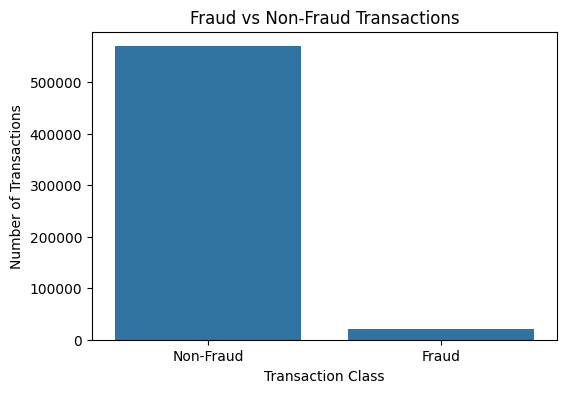

In [27]:
# Create a bar chart showing the class distribution
plt.figure(figsize=(6,4))

sns.barplot(data=fraud_distribution_pd,x="Class", y="count")

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

In [28]:
# Calculate the percentage of each transaction class
total_transactions = fraud_distribution_pd["count"].sum()

fraud_distribution_pd["Percentage"] = (fraud_distribution_pd["count"] /
    total_transactions * 100).round(2)

fraud_distribution_pd

,isFraud,count,Class,Percentage
0,0,569877,Non-Fraud,96.5
1,1,20663,Fraud,3.5


### Observation

The dataset is highly imbalanced, with non-fraudulent transactions representing the majority of observations. Fraudulent transactions account for only a small proportion of the dataset. This class imbalance should be considered during model development, as it may bias the models towards predicting the majority class.

### Transaction Amount Distribution

This analysis examines how transaction amounts are distributed and whether unusually large values are present.

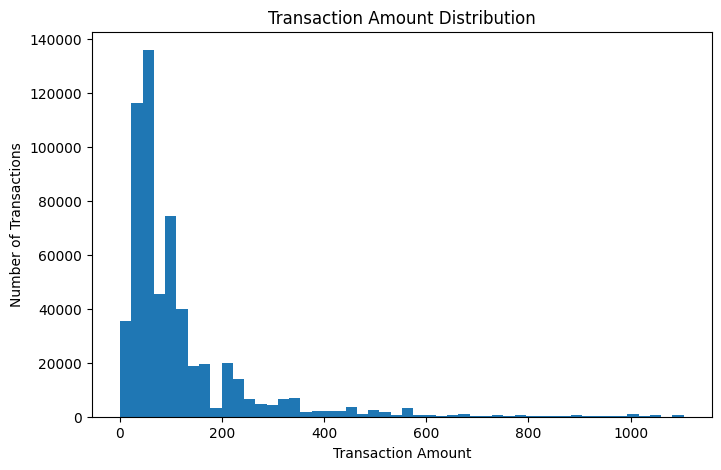

In [29]:
# Select transaction amount and convert it to Pandas
transaction_amount_pd = (fraud_df.select("TransactionAmt").toPandas())

#Calculate the 99th percentile
limit = transaction_amount_pd["TransactionAmt"].quantile(0.99)

#Create a histogram fo transaction amounts
plt.figure(figsize=(8,5))
plt.hist(transaction_amount_pd[transaction_amount_pd["TransactionAmt"] <= limit
    ]["TransactionAmt"],
    bins=50
)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.show()

### Observation

The transaction amounts are positively skewed, with most transactions occurring at lower values. As the transaction amount increases, the number of transactions decreases significantly. A small number of high-value transactions are present, indicating the existence of outliers.

### Product Category Distribution

This analysis examines the distribution of product categories (ProductCD) to identify which product types occur most frequently in the dataset.

In [30]:
# count transactions for each product category
product_distribution = (fraud_df.groupBy("ProductCD").count().orderBy("count", 
                        ascending=False))
product_distribution.show()

+---------+------+
|ProductCD| count|
+---------+------+
|        W|439670|
|        C| 68519|
|        R| 37699|
|        H| 33024|
|        S| 11628|
+---------+------+



In [31]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualisation
product_distribution_pd = product_distribution.toPandas()

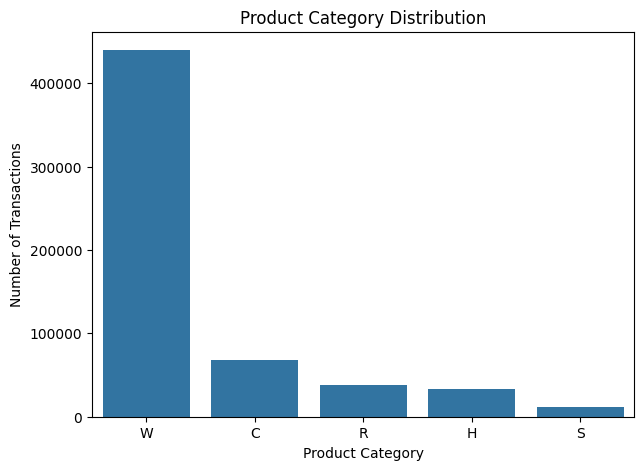

In [32]:
# Create a bar chart showing the product category distribution

plt.figure(figsize=(7,5))
sns.barplot(data=product_distribution_pd,x="ProductCD", y="count")
plt.title("Product Category Distribution")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.show()

In [33]:
# Calculate the percentage of each product category
total_transactions = product_distribution_pd["count"].sum()
product_distribution_pd["Percentage"] = (product_distribution_pd["count"] / 
                                        total_transactions*100).round(2)
product_distribution_pd

,ProductCD,count,Percentage
0,W,439670,74.45
1,C,68519,11.60
2,R,37699,6.38
3,H,33024,5.59
4,S,11628,1.97


### Observation

The ProductCD distribution is highly uneven. Product category **W** is the most common, representing **74.45%** of all transactions. Categories **C**, **R**, **H**, and **S** occur much less frequently, with **S** being the least common at **1.97%**. This indicates that transactions are concentrated within a single product category.

### Card Network Distribution

This analysis examines the distribution of card networks used in the transactions.

In [34]:
# Count Transaction for each card network
card4_distribution = ( fraud_df.groupBy("card4").count().orderBy("count", ascending=False))

card4_distribution.show()

+----------------+------+
|           card4| count|
+----------------+------+
|            visa|384767|
|      mastercard|189217|
|american express|  8328|
|        discover|  6651|
|            NULL|  1577|
+----------------+------+



In [35]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualistion
card4_distribution_pd = card4_distribution.toPandas()

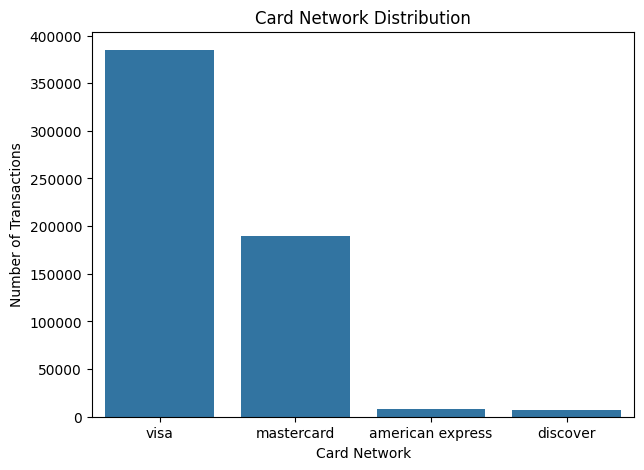

In [36]:
#Create a bar chart showing the card network distribution
plt.figure(figsize=(7,5))
sns.barplot(data=card4_distribution_pd,x="card4", y="count")
plt.title("Card Network Distribution")
plt.xlabel("Card Network")
plt.ylabel("Number of Transactions")
plt.show()

In [37]:
# Calculate the percentage of each card nertwork
total_transactions = card4_distribution_pd["count"].sum()
card4_distribution_pd["Percentage"] = (card4_distribution_pd["count"] / 
                                       total_transactions * 100).round(2)
card4_distribution_pd

,card4,count,Percentage
0,visa,384767,65.16
1,mastercard,189217,32.04
2,american express,8328,1.41
3,discover,6651,1.13
4,None,1577,0.27


### Observation

Visa is the most commonly used card network, accounting for 65.16% of all transactions, followed by Mastercard at 32.04%. American Express and Discover represent only a small proportion of the transactions. A very small number of records (0.27%) have missing card network information.

### Device Type Distribution

This analysis examines the distribution of device types used to perform transactions.

In [38]:
# Count transactions for each device type (excluding missing values)

device_distribution = (fraud_df.filter(col("DeviceType").isNotNull()).
                       groupBy("DeviceType").count().orderBy("count", ascending=False))

device_distribution.show()

+----------+-----+
|DeviceType|count|
+----------+-----+
|   desktop|85165|
|    mobile|55645|
+----------+-----+



In [39]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualisation

device_distribution_pd = device_distribution.toPandas()

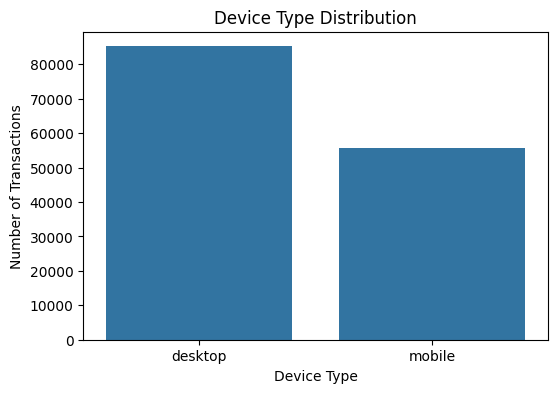

In [40]:
# Create a bar chart showing the device type distribution

plt.figure(figsize=(6,4))

sns.barplot(
    data=device_distribution_pd,
    x="DeviceType",
    y="count"
)

plt.title("Device Type Distribution")
plt.xlabel("Device Type")
plt.ylabel("Number of Transactions")

plt.show()

In [41]:
# Calculate the percentage of each device type

total_transactions = device_distribution_pd["count"].sum()

device_distribution_pd["Percentage"] = (device_distribution_pd["count"] /
    total_transactions * 100).round(2)

device_distribution_pd

,DeviceType,count,Percentage
0,desktop,85165,60.48
1,mobile,55645,39.52


### Correlation Heatmap

This analysis examines the relationships between the selected numerical features using a correlation heatmap.

In [42]:
# Select numerical coulmns and convert to Pandas
correlation_pd = fraud_df.select(numerical_columns).toPandas()

In [43]:
# Calculate the correlation matrix
correlation_matrix = correlation_pd.corr(numeric_only=True)

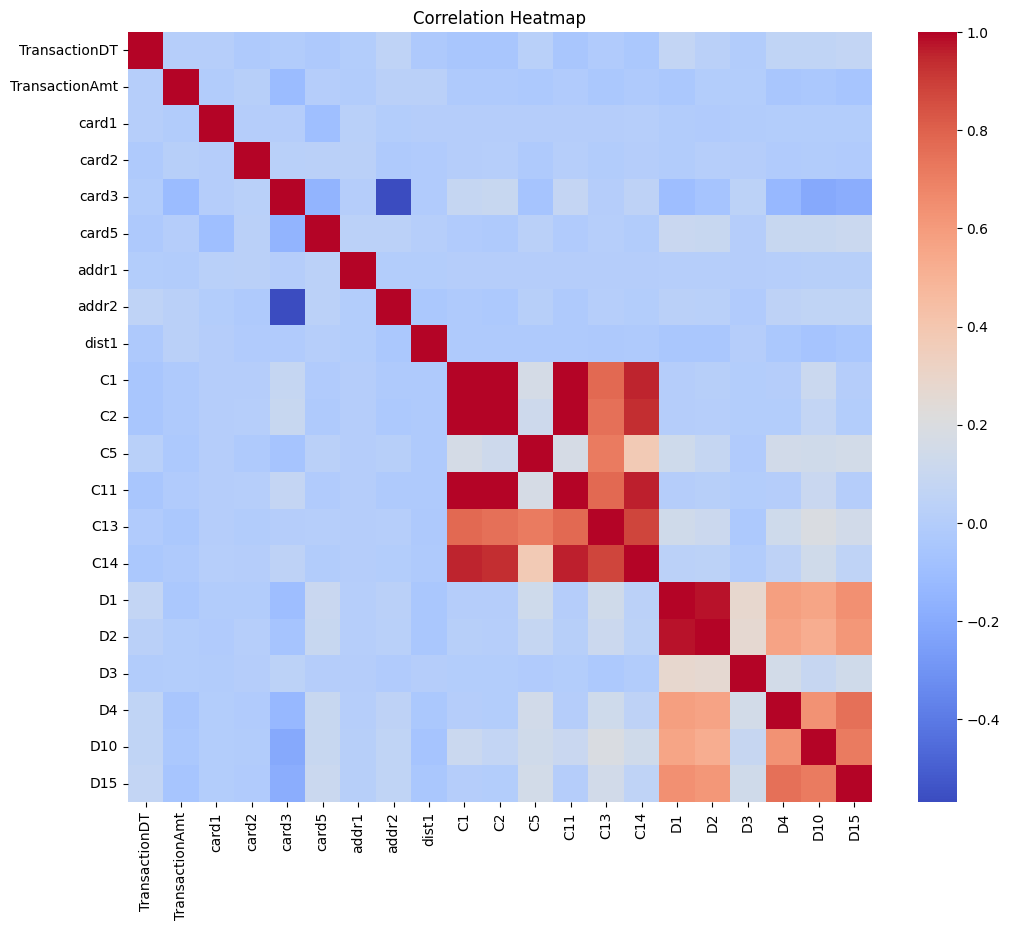

In [44]:
#Create the correlation heatmap
plt.figure(figsize=(12,10))

sns.heatmap(correlation_matrix, cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

### Observation

Most numerical features exhibit weak correlations, indicating limited linear relationships between them. However, the C-series and D-series features show moderate positive correlations, suggesting that these variables contain related information that may contribute to fraud detection.

## Spark SQL Analysis

Spark SQL is used to query the cleaned dataset and generate additional insights related to fraudulent transactions before building the machine learning models.

In [45]:
# Create a temporary SQL view
training_df.createOrReplaceTempView("fraud_data")


In [46]:
#Display the first five records using Spark SQL
spark.sql("""
SELECT* 
FROM fraud_data 
LIMIT 5""").show()

+-------------+-------+-------------+--------------+---------+-----+-----+-----+----------+-----+------+-----+-----+-----+---+---+---+---+----+---+-----+-----+----+----+----+-----+----------+
|TransactionID|isFraud|TransactionDT|TransactionAmt|ProductCD|card1|card2|card3|     card4|card5| card6|addr1|addr2|dist1| C1| C2| C5|C11| C13|C14|   D1|   D2|  D3|  D4| D10|  D15|DeviceType|
+-------------+-------+-------------+--------------+---------+-----+-----+-----+----------+-----+------+-----+-----+-----+---+---+---+---+----+---+-----+-----+----+----+----+-----+----------+
|      2987000|      0|        86400|          68.5|        W|13926|361.0|150.0|  discover|142.0|credit|315.0| 87.0| 19.0|1.0|1.0|0.0|2.0| 1.0|1.0| 14.0| 95.0|13.0|24.0|13.0|  0.0|   desktop|
|      2987001|      0|        86401|          29.0|        W| 2755|404.0|150.0|mastercard|102.0|credit|325.0| 87.0|  8.0|1.0|1.0|0.0|1.0| 1.0|1.0|  0.0| 95.0| 8.0| 0.0| 0.0|  0.0|   desktop|
|      2987003|      0|        86499|   

In [47]:
# Count fraud and non-fraud transactions
fraud_sql = spark.sql("""
SELECT 
    isFraud, 
    COUNT(*) AS Total_Transactions 
    FROM fraud_data
    GROUP BY isFraud 
    ORDER BY isFraud
    """)
fraud_sql.show()

+-------+------------------+
|isFraud|Total_Transactions|
+-------+------------------+
|      0|            455922|
|      1|             16482|
+-------+------------------+



In [48]:
# Calculate the average transaction amount for each class
average_transaction_sql = spark.sql(""" 
SELECT isFraud, 
ROUND(AVG(TransactionAmt),2)AS Average_Transaction_Amount 
FROM fraud_data 
GROUP BY isFraud 
ORDER BY isFraud
""")

average_transaction_sql.show()

+-------+--------------------------+
|isFraud|Average_Transaction_Amount|
+-------+--------------------------+
|      0|                    134.69|
|      1|                    147.26|
+-------+--------------------------+



In [49]:
#Calculate fraud transactions for each product category
product_sql =spark.sql("""
SELECT
    ProductCD,
    COUNT(*) AS Total_Transactions,
    SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS Fraud_Trnasactions,
    ROUND(SUM(CASE WHEN isFraud =1 Then 1 ELSE 0 END)
    / COUNT(*)*100, 2) AS Fraud_Percentage
FROM fraud_data
GROUP BY ProductCD
ORDER BY Fraud_Percentage DESC
""")
product_sql.show()

+---------+------------------+------------------+----------------+
|ProductCD|Total_Transactions|Fraud_Trnasactions|Fraud_Percentage|
+---------+------------------+------------------+----------------+
|        C|             55002|              6435|            11.7|
|        S|              9325|               544|            5.83|
|        H|             26384|              1247|            4.73|
|        R|             30131|              1131|            3.75|
|        W|            351562|              7125|            2.03|
+---------+------------------+------------------+----------------+



In [50]:
# Calculate fraud transactions for each card nertwork
card_sql = spark.sql("""
SELECT
    card4,
    COUNT(*) AS Total_Transactions,
    SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS Fraud_Transactions,
    ROUND(SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END)
    /COUNT(*)*100, 2) AS Fraud_Percentage
FROM fraud_data
GROUP BY card4
ORDER BY Fraud_Percentage DESC
""")
card_sql.show()

+----------------+------------------+------------------+----------------+
|           card4|Total_Transactions|Fraud_Transactions|Fraud_Percentage|
+----------------+------------------+------------------+----------------+
|        discover|              5315|               405|            7.62|
|            visa|            309258|             10701|            3.46|
|      mastercard|            151173|              5187|            3.43|
|american express|              6658|               189|            2.84|
+----------------+------------------+------------------+----------------+



In [51]:
#Calculate fraud transactions for each device type
device_sql = spark.sql("""
SELECT 
    DeviceType,
    COUNT(*) AS Total_Transactions,
    SUM(CASE WHEN isFraud = 1 THEN 1 ELSE 0 END) AS Fraud_Transactions,
    ROUND(SUM(CASE WHEN isFraud =1 THEN 1 ELSE 0 END)
    / COUNT(*)*100, 2) AS Fraud_Percentage
FROM fraud_data
GROUP BY DeviceType
ORDER BY Fraud_Percentage DESC
""")
device_sql.show()

+----------+------------------+------------------+----------------+
|DeviceType|Total_Transactions|Fraud_Transactions|Fraud_Percentage|
+----------+------------------+------------------+----------------+
|    mobile|             44570|              4508|           10.11|
|   desktop|            427834|             11974|             2.8|
+----------+------------------+------------------+----------------+



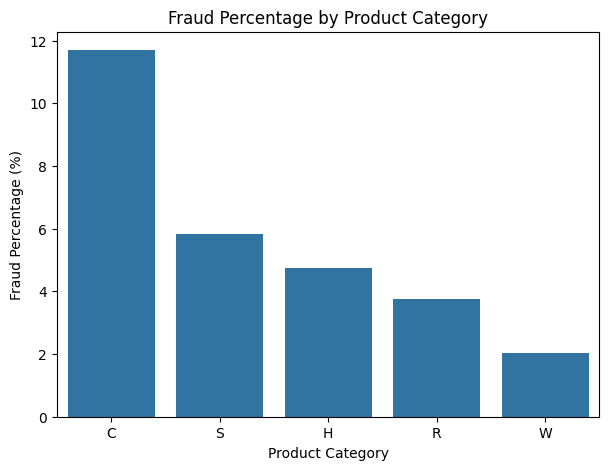

In [52]:
product_sql_pd = product_sql.toPandas()

plt.figure(figsize=(7,5))

sns.barplot(
    data=product_sql_pd,
    x="ProductCD",
    y="Fraud_Percentage"
)

plt.title("Fraud Percentage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Fraud Percentage (%)")

plt.show()

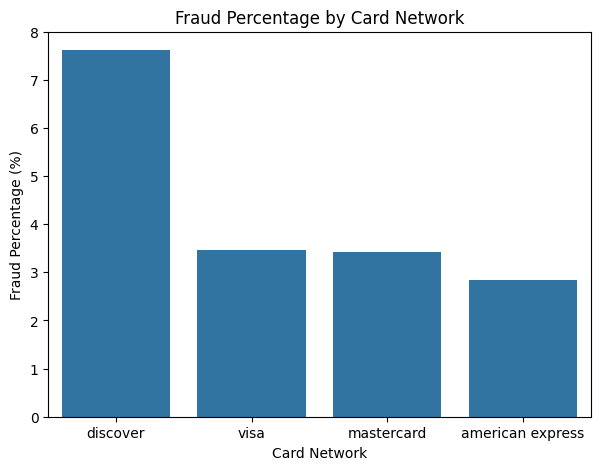

In [53]:
card_sql_pd = card_sql.toPandas()

plt.figure(figsize=(7,5))

sns.barplot(
    data=card_sql_pd,
    x="card4",
    y="Fraud_Percentage"
)

plt.title("Fraud Percentage by Card Network")
plt.xlabel("Card Network")
plt.ylabel("Fraud Percentage (%)")

plt.show()

In [54]:
# Create a StringIndexer for each categorical column
indexers = [StringIndexer(inputCol=column, outputCol=column + "_Index", 
                          handleInvalid="keep") for column in categorical_columns]

In [55]:
# Fit the indexers on the training data and apply them to both datasets
for indexer in indexers:
    model = indexer.fit(training_df)
    training_df = model.transform(training_df)
    testing_df = model.transform(testing_df)

In [56]:
training_df.select(
    "ProductCD",
    "ProductCD_Index",
    "card4",
    "card4_Index",
    "card6",
    "card6_Index",
    "DeviceType",
    "DeviceType_Index"
).show(10, truncate=False)

+---------+---------------+----------+-----------+------+-----------+----------+----------------+
|ProductCD|ProductCD_Index|card4     |card4_Index|card6 |card6_Index|DeviceType|DeviceType_Index|
+---------+---------------+----------+-----------+------+-----------+----------+----------------+
|W        |0.0            |discover  |3.0        |credit|1.0        |desktop   |0.0             |
|W        |0.0            |mastercard|1.0        |credit|1.0        |desktop   |0.0             |
|W        |0.0            |mastercard|1.0        |debit |0.0        |desktop   |0.0             |
|H        |3.0            |mastercard|1.0        |credit|1.0        |mobile    |1.0             |
|W        |0.0            |visa      |0.0        |debit |0.0        |desktop   |0.0             |
|W        |0.0            |visa      |0.0        |debit |0.0        |desktop   |0.0             |
|W        |0.0            |mastercard|1.0        |debit |0.0        |desktop   |0.0             |
|C        |1.0      

In [57]:
# Define the input features for machine learning

feature_columns = [
    "TransactionDT",
    "TransactionAmt",
    "card1",
    "card2",
    "card3",
    "card5",
    "addr1",
    "addr2",
    "dist1",
    "C1",
    "C2",
    "C5",
    "C11",
    "C13",
    "C14",
    "D1",
    "D2",
    "D3",
    "D4",
    "D10",
    "D15",
    "ProductCD_Index",
    "card4_Index",
    "card6_Index",
    "DeviceType_Index"
]

In [58]:
# Combine the selected features into one features column
assembler = VectorAssembler(inputCols=feature_columns,outputCol="features")

In [59]:
training_df = assembler.transform(training_df)
testing_df = assembler.transform(testing_df)

In [60]:
training_df.select("features", "isFraud").show(5, truncate=False)

+--------------------------------------------------------------------------------------------------------------------------------+-------+
|features                                                                                                                        |isFraud|
+--------------------------------------------------------------------------------------------------------------------------------+-------+
|[86400.0,68.5,13926.0,361.0,150.0,142.0,315.0,87.0,19.0,1.0,1.0,0.0,2.0,1.0,1.0,14.0,95.0,13.0,24.0,13.0,0.0,0.0,3.0,1.0,0.0]   |0      |
|[86401.0,29.0,2755.0,404.0,150.0,102.0,325.0,87.0,8.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,95.0,8.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0]         |0      |
|[86499.0,50.0,18132.0,567.0,150.0,117.0,476.0,87.0,8.0,2.0,5.0,0.0,1.0,25.0,1.0,112.0,112.0,0.0,94.0,84.0,111.0,0.0,1.0,0.0,0.0]|0      |
|[86506.0,50.0,4497.0,514.0,150.0,102.0,420.0,87.0,8.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,95.0,8.0,24.0,14.0,50.0,3.0,1.0,1.0,1.0]      |0      |
|[86510.0,49.0,5937.0,555.0

In [61]:
#Seprate fraud and non-fraud transactions
fraud_train = training_df.filter(col("isFraud") == 1)

non_fraud_train = training_df.filter(col("isFraud") == 0)

In [62]:
#Count each class
fraud_count = fraud_train.count()
non_fraud_count = non_fraud_train.count()

print("Fraud Transactions:", fraud_count)
print("Non-Fraud Transactions:", non_fraud_count)


Fraud Transactions: 16482
Non-Fraud Transactions: 455922


In [63]:
# Calculate the sampling fraction
sampling_fraction = fraud_count / non_fraud_count
print("Sampling Fraction:", sampling_fraction)

Sampling Fraction: 0.03615092055219972


In [64]:
# Randomly sample the non_fraud class
non_fraud_sample =  non_fraud_train.sample(withReplacement=False,fraction=sampling_fraction,
                                          seed=42)
# Create a balanced training dataset
balanced_training_df = fraud_train.union(non_fraud_sample)

In [65]:
balanced_training_df.groupBy("isFraud").count().show()

+-------+-----+
|isFraud|count|
+-------+-----+
|      1|16482|
|      0|16666|
+-------+-----+



##  Model Evaluation

This section evaluates the performance of three machine learning models for fraud detection:

- Logistic Regression
- Decision Tree
- Random Forest

The models are compared using Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices, and feature importance to determine the most effective model for detecting fraudulent financial transactions.

## Logistic Regression

In [66]:
# Create the logistic Regression model

lr = LogisticRegression(featuresCol="features", labelCol="isFraud")

# Train the model using the balanced training data
lr_model = lr.fit(balanced_training_df)

#Predict fraud on the testing data
lr_predictions = lr_model.transform(testing_df)

In [67]:
lr_predictions.select(
    "isFraud",
    "prediction",
    "probability").show(5,truncate=False)

+-------+----------+----------------------------------------+
|isFraud|prediction|probability                             |
+-------+----------+----------------------------------------+
|0      |0.0       |[0.7571582509912638,0.24284174900873623]|
|0      |0.0       |[0.7553429758861845,0.2446570241138155] |
|0      |1.0       |[0.46233668207634904,0.537663317923651] |
|0      |0.0       |[0.673358024862249,0.32664197513775095] |
|0      |0.0       |[0.6243323436918797,0.37566765630812027]|
+-------+----------+----------------------------------------+
only showing top 5 rows


In [68]:

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="isFraud",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

lr_roc_auc = roc_evaluator.evaluate(lr_predictions)

# Accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="isFraud",
    predictionCol="prediction",
    metricName="accuracy"
)

lr_accuracy = accuracy_evaluator.evaluate(lr_predictions)

# Precision
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="isFraud",
    predictionCol="prediction",
    metricName="weightedPrecision"
)

lr_precision = precision_evaluator.evaluate(lr_predictions)

# Recall
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="isFraud",
    predictionCol="prediction",
    metricName="weightedRecall"
)

lr_recall = recall_evaluator.evaluate(lr_predictions)

# F1-score
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="isFraud",
    predictionCol="prediction",
    metricName="f1"
)

lr_f1 = f1_evaluator.evaluate(lr_predictions)

print("Logistic Regression Results")
print(f"Accuracy: {lr_accuracy * 100:.2f}%")
print(f"Precision: {lr_precision * 100:.2f}%")
print(f"Recall: {lr_recall * 100:.2f}%")
print(f"F1-score: {lr_f1 * 100:.2f}%")
print(f"ROC-AUC: {lr_roc_auc * 100:.2f}%")

Logistic Regression Results
Accuracy: 73.45%
Precision: 95.15%
Recall: 73.45%
F1-score: 81.81%
ROC-AUC: 77.11%


/usr/local/lib/python3.12/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


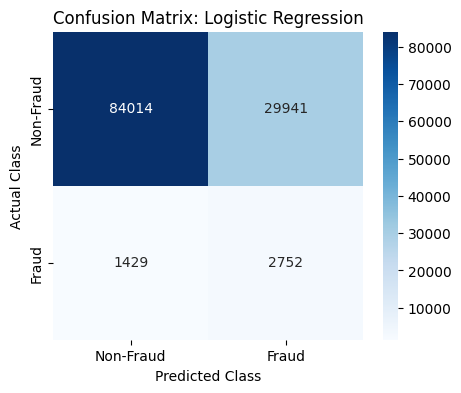

In [69]:
# Create the confusion matrix for the Random Forest model

lr_preds_and_labels = (
    lr_predictions
    .select("prediction", "isFraud")
    .rdd
    .map(lambda row: (
        float(row["prediction"]),
        float(row["isFraud"])
    ))
)

lr_metrics = MulticlassMetrics(lr_preds_and_labels)

lr_confusion_matrix = lr_metrics.confusionMatrix().toArray()

# Plot the confusion matrix

plt.figure(figsize=(5,4))

sns.heatmap(
    lr_confusion_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Confusion Matrix: Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

## Decision Tree

In [70]:
# Create the Decision Tree model

dt = DecisionTreeClassifier(featuresCol="features", labelCol="isFraud", seed=42)

# Train the model using the balanced training data
dt_model = dt.fit(balanced_training_df)

#Predict fraud on the testing data
dt_predictions = dt_model.transform(testing_df)

In [71]:
dt_predictions.select(
    "isFraud",
    "prediction",
    "probability").show(5,truncate=False)

+-------+----------+----------------------------------------+
|isFraud|prediction|probability                             |
+-------+----------+----------------------------------------+
|0      |0.0       |[0.6796913641309724,0.3203086358690276] |
|0      |0.0       |[0.6796913641309724,0.3203086358690276] |
|0      |0.0       |[0.6796913641309724,0.3203086358690276] |
|0      |0.0       |[0.8819622964867181,0.11803770351328192]|
|0      |0.0       |[0.5086206896551724,0.49137931034482757]|
+-------+----------+----------------------------------------+
only showing top 5 rows


In [72]:

# ROC-AUC

dt_roc_auc = roc_evaluator.evaluate(dt_predictions)

# Accuracy

dt_accuracy = accuracy_evaluator.evaluate(dt_predictions)

# Precision

dt_precision = precision_evaluator.evaluate(dt_predictions)

# Recall

dt_recall = recall_evaluator.evaluate(dt_predictions)

# F1-score

dt_f1 = f1_evaluator.evaluate(dt_predictions)

print("Decision Tree Results")
print(f"Accuracy: {dt_accuracy * 100:.2f}%")
print(f"Precision: {dt_precision * 100:.2f}%")
print(f"Recall: {dt_recall * 100:.2f}%")
print(f"F1-score: {dt_f1 * 100:.2f}%")
print(f"ROC-AUC: {dt_roc_auc * 100:.2f}%")

Decision Tree Results
Accuracy: 83.22%
Precision: 95.58%
Recall: 83.22%
F1-score: 88.17%
ROC-AUC: 66.24%


/usr/local/lib/python3.12/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


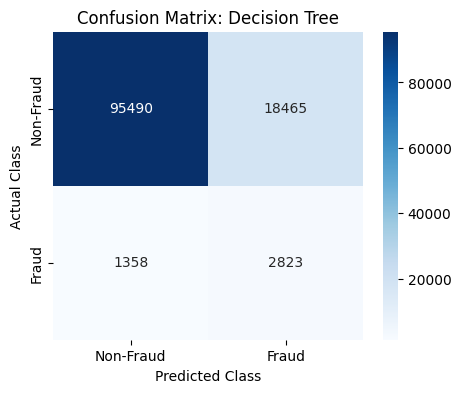

In [73]:
# Create the confusion matrix for the Decision Tree model

dt_preds_and_labels = (
    dt_predictions
    .select("prediction", "isFraud")
    .rdd
    .map(lambda row: (
        float(row["prediction"]),
        float(row["isFraud"])
    ))
)

dt_metrics = MulticlassMetrics(dt_preds_and_labels)

dt_confusion_matrix = dt_metrics.confusionMatrix().toArray()

# Plot the confusion matrix

plt.figure(figsize=(5,4))

sns.heatmap(
    dt_confusion_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Confusion Matrix: Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()


## Random Forest

In [74]:
# Create the Random Forest model

rf = RandomForestClassifier(featuresCol="features", labelCol="isFraud", numTrees=100,seed=42)

# Train the model using the balanced training data
rf_model = rf.fit(balanced_training_df)

#Predict fraud on the testing data
rf_predictions = rf_model.transform(testing_df)

In [75]:

# ROC-AUC

rf_roc_auc = roc_evaluator.evaluate(rf_predictions)

# Accuracy

rf_accuracy = accuracy_evaluator.evaluate(rf_predictions)

# Precision

rf_precision = precision_evaluator.evaluate(rf_predictions)

# Recall

rf_recall = recall_evaluator.evaluate(rf_predictions)

# F1-score

rf_f1 = f1_evaluator.evaluate(rf_predictions)

print("Random Forest Results")
print(f"Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall: {rf_recall * 100:.2f}%")
print(f"F1-score: {rf_f1 * 100:.2f}%")
print(f"ROC-AUC: {rf_roc_auc * 100:.2f}%")

Random Forest Results
Accuracy: 83.65%
Precision: 95.76%
Recall: 83.65%
F1-score: 88.46%
ROC-AUC: 85.39%


/usr/local/lib/python3.12/dist-packages/pyspark/sql/context.py:157: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


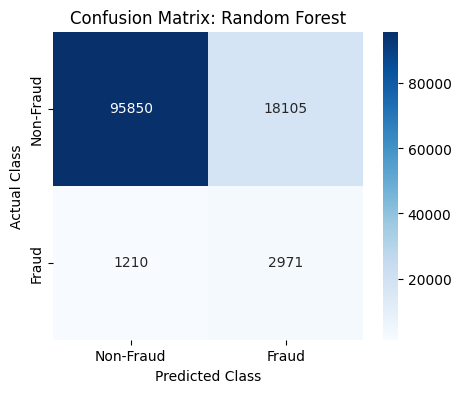

In [76]:
# Create the confusion matrix for the Random Forest model

rf_preds_and_labels = (
    rf_predictions
    .select("prediction", "isFraud")
    .rdd
    .map(lambda row: (
        float(row["prediction"]),
        float(row["isFraud"])
    ))
)

rf_metrics = MulticlassMetrics(rf_preds_and_labels)

rf_confusion_matrix = rf_metrics.confusionMatrix().toArray()

# Plot the confusion matrix

plt.figure(figsize=(5,4))

sns.heatmap(
    rf_confusion_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Confusion Matrix: Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

# Model Comparison
The performance of the three machine learning models is compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC. This comparison helps identify the most suitable model for detecting fraudulent financial transactions.

In [77]:
comparison_table = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", 'Random Forest'],
    "Accuracy": [lr_accuracy * 100, dt_accuracy * 100, rf_accuracy * 100 ],
    "Precision": [lr_precision * 100, dt_precision * 100,rf_precision * 100 ],
    "Recall": [lr_recall * 100, dt_recall * 100, rf_recall * 100],
    "F1-Score": [lr_f1 * 100, dt_f1 * 100, rf_f1 * 100],
    "ROC-AUC": [lr_roc_auc * 100, dt_roc_auc * 100, rf_roc_auc * 100]
})

# Print the comparison table
comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,73.445859,95.145504,73.445859,81.813565,77.108081
1,Decision Tree,83.220187,95.577612,83.220187,88.174659,66.239346
2,Random Forest,83.650200,95.757227,83.650200,88.464056,85.389113


## Feature Importance

In [78]:
# Extract feature importance scores from the Random Forest model

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.featureImportances.toArray()
})

# Sort features from highest to lowest importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the feature importance table

feature_importance

,Feature,Importance
11,C5,0.146254
4,card3,0.115766
9,C1,0.088063
21,ProductCD_Index,0.085444
13,C13,0.083301
17,D3,0.083101
14,C14,0.079027
12,C11,0.066494
10,C2,0.053864
16,D2,0.046007


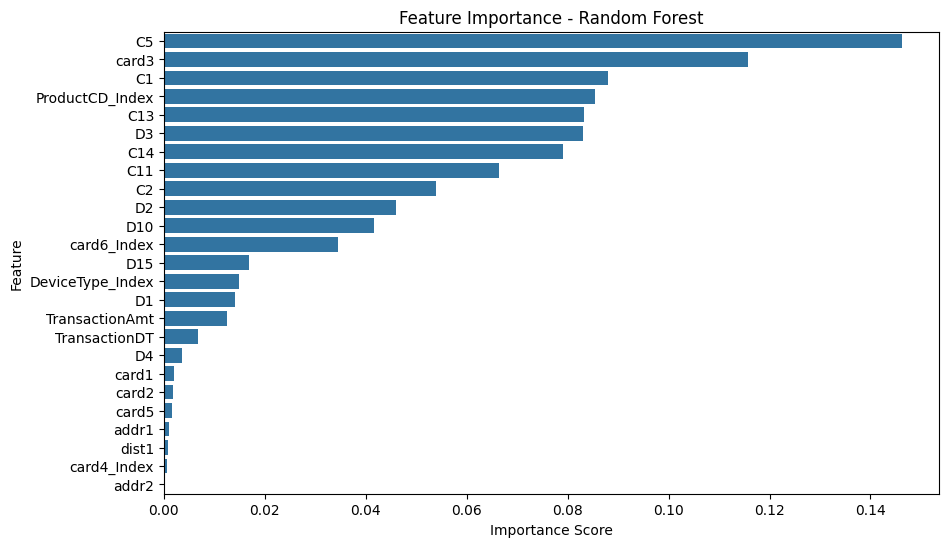

In [79]:
# Create a bar chart of feature importance

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.show()

# Conclusion

This project developed and evaluated three machine learning models for detecting fraudulent financial transactions using Apache Spark MLlib.

The models evaluated were:

- Logistic Regression
- Decision Tree
- Random Forest

The evaluation was based on Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Among the three models, Random Forest achieved the best overall performance with:

- Accuracy: 83.65%
- Precision: 95.76%
- Recall: 83.65%
- F1-score: 88.46%
- ROC-AUC: 85.39%

These results indicate that Random Forest was the most effective model for distinguishing fraudulent transactions from legitimate transactions in this dataset.

Future work could include hyperparameter tuning, additional feature engineering, and evaluating more advanced machine learning algorithms to further improve fraud detection performance.

In [ ]:
#fraud_distribution_pd.to_csv("fraud_distribution.csv", index=False)

In [ ]:
#product_distribution_pd.to_csv("product_distribution.csv",index=False)


In [ ]:
#card4_distribution_pd.to_csv("card_distribution.csv", index=False)



In [ ]:
#device_distribution_pd.to_csv("device_distribution.csv", index=False)



In [ ]:
#feature_importance.to_csv("feature_importance.csv", index=False)



In [ ]:
#comparison_table.to_csv("model_comparison.csv", index=False)

In [ ]:
#transaction_amount_pd.to_csv("transaction_amount.csv", index=False)